<a href="https://colab.research.google.com/github/KeshavGoyal-dot/UCS420-Cognitive-Computing/blob/main/UCS420_Assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 7 — NLP Text Preprocessing


In [ ]:
ROLL_NO = 10241703187          # <-- your full roll number
NAME = "Keshav Goyal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 10241703187   Name: Keshav Goyal   Fingerprint: 1CD23E7B   Tickets: 14

Ticket_ID                                                               Ticket_Text
      T01                 The email has stopped syncing. Is there another solution?
      T02               The Matlab keeps disconnecting. I have tried several times!
      T03  Student portal keeps disconnecting since yesterday. It worked yesterday.
      T04                          The VPN keeps disconnecting. Can you check this?
      T05     I am unable to use the lms during the lab. Is there another solution?
      T06          I can't open the VPN during the lab. I have tried several times!
      T07                                        Dr. Rao's lab PC (No. 14) is down.
      T08                                      The VPN failed to open. Please help.
      T09                                               The file is 95.5% uploaded.
      T10                              Call me on +91 98765 43210 or 0175-2

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
processed = {row.Ticket_ID: process_ticket(row.Ticket_Text)
             for row in df.itertuples(index=False)}

q1_rows = []
for ticket_id in df["Ticket_ID"]:
    p = processed[ticket_id]
    q1_rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(p["sentences"]),
        "Tokens": len(p["tokens"]),
        "Punctuation": len(p["punct"]),
        "Stopwords": len(p["stops"]),
        "Unique tokens": len(set(p["tokens"])),
        "Final tokens": len(p["final"]),
    })

q1_table = pd.DataFrame(q1_rows)
total_cols = ["Sentences", "Tokens", "Punctuation", "Stopwords", "Unique tokens", "Final tokens"]
q1_total = {"Ticket_ID": "TOTAL"}
for col in total_cols:
    q1_total[col] = q1_table[col].sum()
q1_table = pd.concat([q1_table, pd.DataFrame([q1_total])], ignore_index=True)

print(q1_table.to_string(index=False))

selected_id = FOCUS[0]
selected = processed[selected_id]
print(f"\n--- Selected ticket: {selected_id} ---")
print("Tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique tokens  Final tokens
      T01          2      11            2          4             11             5
      T02          2      11            2          3             11             6
      T03          2      11            2          1              9             8
      T04          2      10            2          4             10             4
      T05          2      16            2          8             15             6
      T06          2      16            2          6             14             8
      T07          2      13            4          3             12             6
      T08          2       9            2          2              8             5
      T09          1       7            2          2              7             3
      T10          1       9            1          3              9             5
      T11          2      13            2          5             12             6
      T12       

# These are artifacts created by word_tokenize() when contractions are split.
weird_final = sorted({
    tok for ticket_id in processed
    for tok in processed[ticket_id]["final"]
    if tok in {"n't", "'s", "'m", "'re", "'ve", "'d", "'ll", "ca", "wo"}
})
print("Examples of non-lexical-looking final tokens:", weird_final)
print("They come from NLTK word_tokenize() splitting contractions, e.g. can't -> ca + n't.")

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
from collections import Counter
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.tokenize import RegexpTokenizer
from nltk.util import ngrams
import matplotlib.pyplot as plt

# Regex patterns
LONG_WORD_RE = r"\b[A-Za-z]{6,}\b"
NUMBER_RE = r"\b\d+(?:\.\d+){1,2}\b|\b\d{1,3}(?:,\d{3})+\b|\b\d+\b"
CAPITAL_RE = r"\b[A-Z][A-Za-z]*\b"
VOWEL_WORD_RE = r"\b[AEIOUaeiou][A-Za-z]*\b"

EMAIL_RE = r"\b[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+"
URL_RE = r"https?://[^\s<>\"]+|www\.[^\s<>\"]+"
PHONE_RE = r"(?:\+91[-\s]?\d{5}[-\s]?\d{5}|\d{4}[-\s]\d{3}[-\s]\d{4})"

raw_tickets = df["Ticket_Text"].tolist()

print("--- Q2: findall extraction ---")
for label, pattern in [
    ("Words longer than 5 letters", LONG_WORD_RE),
    ("Numbers", NUMBER_RE),
    ("Capitalized words", CAPITAL_RE),
    ("Words beginning with a vowel", VOWEL_WORD_RE),
]:
    values = []
    for text in raw_tickets:
        values.extend(re.findall(pattern, text))
    print(f"\n{label}: {values}")

def redact_contacts(text):
    text = re.sub(EMAIL_RE, "<EMAIL>", text)
    text = re.sub(URL_RE, "<URL>", text)
    text = re.sub(PHONE_RE, "<PHONE>", text)
    return text

print("\n--- Replacement on raw tickets ---")
for ticket_id, text in df[["Ticket_ID", "Ticket_Text"]].itertuples(index=False):
    redacted = redact_contacts(text)
    if redacted != text:
        print(f"{ticket_id}\n  BEFORE: {text}\n  AFTER : {redacted}")

print("\n--- TEST_LINES replacement check ---")
for line in TEST_LINES:
    print(redact_contacts(line))

--- Q2: findall extraction ---

Words longer than 5 letters: ['stopped', 'syncing', 'another', 'solution', 'Matlab', 'disconnecting', 'several', 'Student', 'portal', 'disconnecting', 'yesterday', 'worked', 'yesterday', 'disconnecting', 'unable', 'during', 'another', 'solution', 'during', 'several', 'failed', 'Please', 'uploaded', 'crashes', 'opening', 'changed', 'disconnecting', 'resetting', 'password', 'reinstalled', 'MATLAB', 'during', 'changed']

Numbers: ['14', '95.5', '91', '98765', '43210', '0175', '239', '3201']

Capitalized words: ['The', 'Is', 'The', 'Matlab', 'I', 'Student', 'It', 'The', 'VPN', 'Can', 'I', 'Is', 'I', 'VPN', 'I', 'Dr', 'Rao', 'PC', 'No', 'The', 'VPN', 'Please', 'The', 'Call', 'The', 'WiFi', 'I', 'The', 'Wi', 'Fi', 'VPN', 'Wifi', 'Can', 'I', 'MATLAB', 'I']

Words beginning with a vowel: ['email', 'Is', 'another', 'I', 'It', 'I', 'am', 'unable', 'use', 'Is', 'another', 'I', 'open', 'I', 'is', 'open', 'is', 'uploaded', 'on', 'or', 'opening', 'I', 'after', 'I', 'I

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# One RegexpTokenizer pattern. The alternatives are ordered from the most
# specific multi-character forms to ordinary words/numbers.
TOKEN_PATTERN = (
    r"https?://[^\s<>\"]+|www\.[^\s<>\"]+"
    r"|[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+"
    r"|(?:\+91[-\s]?\d{5}[-\s]?\d{5}|\d{4}[-\s]\d{3}[-\s]\d{4})"
    r"|\d+(?:\.\d+){1,2}"
    r"|[A-Za-z]+(?:[-'][A-Za-z]+)+"
    r"|[A-Za-z]+(?:'[A-Za-z]+)?"
    r"|\d+(?:,\d{3})*"
    r"|[^\w\s]"
)

CUSTOM_TOKENIZER = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return CUSTOM_TOKENIZER.tokenize(text)

print("--- my_tokenize(TEST_LINES) ---")
for line in TEST_LINES:
    print(my_tokenize(line))

comparison_rows = []
different_tickets = 0
for row in df.itertuples(index=False):
    custom = my_tokenize(row.Ticket_Text)
    standard = word_tokenize(row.Ticket_Text)
    same = custom == standard
    if not same:
        different_tickets += 1
    comparison_rows.append({
        "Ticket_ID": row.Ticket_ID,
        "my_tokenize": custom,
        "word_tokenize": standard,
        "Different": not same
    })

comparison_df = pd.DataFrame(comparison_rows)
print(f"\nTickets tokenized differently: {different_tickets} / {len(df)}")
print(comparison_df[comparison_df["Different"]][["Ticket_ID", "my_tokenize", "word_tokenize"]].to_string(index=False))

print("\nExamples of differences:")
for line in TEST_LINES:
    print("\nText:", line)
    print("Custom :", my_tokenize(line))
    print("NLTK   :", word_tokenize(line))

--- my_tokenize(TEST_LINES) ---
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']

Tickets tokenized differently: 6 / 14
Ticket_ID                                                                          my_tokenize                                                                          word_tokenize
      T06   [I, can't, open, the, VPN, during, the, lab, ., I, have, tried, several, times, !]   [I, ca, n't, open, the, VPN, during, the, lab, ., I, have, tried, several, times, !]
      T07                                [Dr, ., Rao's, lab, PC, (, No, ., 14, ), is, down, .]                                  [Dr., Rao, 's, 

print(f"{different_tickets} of {len(df)} tickets have different tokenization.")

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Unique final-token vocabulary
all_final = [tok for ticket_id in processed for tok in processed[ticket_id]["final"]]
unique_final = sorted(set(all_final))

porter = PorterStemmer()
lancaster = LancasterStemmer()
# Dataset contains words such as working, asking, syncing; remove "ing"
# because it is a useful suffix represented by multiple words in this dataset.
regexp_stemmer = RegexpStemmer(r"ing$", min=4)
lemmatizer = WordNetLemmatizer()

def penn_to_wordnet(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

pos_info = dict(pos_tag(unique_final))
stem_rows = []
for word in unique_final:
    pos = pos_info.get(word, "NN")
    wn_pos = penn_to_wordnet(pos)
    lemma = lemmatizer.lemmatize(word, pos=wn_pos)
    stem_rows.append({
        "word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "WordNet lemma": lemma,
        "POS": pos
    })

stem_df = pd.DataFrame(stem_rows)
diff_mask = (
    stem_df[["Porter", "Lancaster", "Regexp", "WordNet lemma"]]
    .nunique(axis=1) > 1
)
stem_differences = stem_df[diff_mask].reset_index(drop=True)

print("Regexp suffix chosen: 'ing' because words such as 'working', 'asking', 'syncing' occur in the dataset.")
print("\nWords where outputs differ:")
print(stem_differences.to_string(index=False))

Regexp suffix chosen: 'ing' because words such as 'working', 'asking', 'syncing' occur in the dataset.

Words where outputs differ:
       word   Porter Lancaster      Regexp WordNet lemma POS
    another    anoth     anoth     another       another  DT
       call     call       cal        call          call  VB
    changed    chang     chang     changed        change VBD
    crashes    crash     crash     crashes         crash NNS
     failed     fail      fail      failed          fail VBD
       file     file       fil        file          file  NN
      keeps     keep      keep       keeps          keep NNS
        lms       lm       lms         lms            lm NNS
       open     open        op        open          open  JJ
    opening     open        op        open          open VBG
     please    pleas     pleas      please        please  NN
     portal   portal      port      portal        portal  JJ
reinstalled reinstal  reinstal reinstalled     reinstall VBD
  resetting   

# Examples can be taken directly from the table above.
print("Over-stemming: a stemmer may reduce different valid words to the same short form.")
print("Under-stemming: related words may remain as different stems when the algorithm is conservative.")
print("Use the displayed table to quote one concrete pair from your generated dataset.")

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Set  Total tokens  Unique tokens      TTR
 S1           164             83 0.506098
 S2           135             76 0.562963
 S3            78             51 0.653846
 S4            78             49 0.628205

Top 10 words of S1:
[('.', 19), ('the', 14), ('i', 7), ('is', 4), ('?', 4), ('keeps', 4), ('disconnecting', 4), ('vpn', 4), ('lab', 4), ("n't", 4)]

Top 10 words of S3:
[('keeps', 4), ('disconnecting', 4), ('vpn', 4), ('lab', 4), ("n't", 4), ('another', 2), ('solution', 2), ('matlab', 2), ('tried', 2), ('several', 2)]


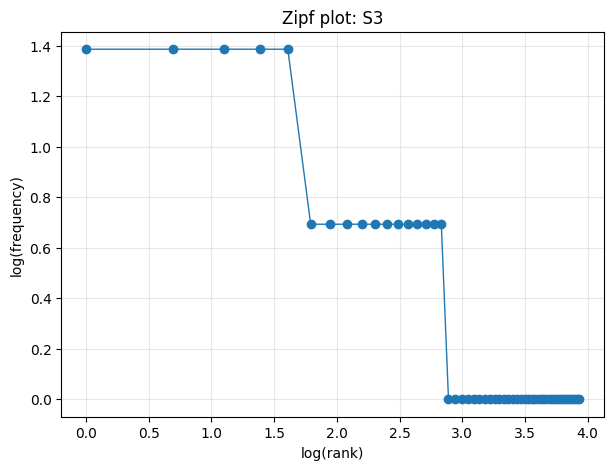


Top 5 bigrams of S1:
[(('.', 'the'), 5), (('keeps', 'disconnecting'), 4), (('.', 'i'), 4), (('the', 'vpn'), 4), (('?', 'i'), 3)]

Top 5 bigrams of S3:
[(('keeps', 'disconnecting'), 4), (('another', 'solution'), 2), (('tried', 'several'), 2), (('several', 'times'), 2), (("n't", 'know'), 2)]


In [ ]:
# S1: all tokens, S2: no punctuation, S3: final tokens, S4: Porter-stemmed S3
S1 = [tok for ticket_id in processed for tok in processed[ticket_id]["tokens"]]
S2 = [tok for ticket_id in processed for tok in processed[ticket_id]["tokens"]
      if not is_punct(tok)]
S3 = [tok for ticket_id in processed for tok in processed[ticket_id]["final"]]
S4 = [porter.stem(tok) for tok in S3]

def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    return total, unique, unique / total if total else 0

stats = pd.DataFrame([
    ["S1", *corpus_stats(S1)],
    ["S2", *corpus_stats(S2)],
    ["S3", *corpus_stats(S3)],
    ["S4", *corpus_stats(S4)],
], columns=["Set", "Total tokens", "Unique tokens", "TTR"])

print(stats.to_string(index=False))

print("\nTop 10 words of S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

# Zipf plot for S3
freqs = sorted(Counter(S3).values(), reverse=True)
ranks = list(range(1, len(freqs) + 1))
plt.figure(figsize=(7, 5))
plt.plot([__import__("math").log(r) for r in ranks],
         [__import__("math").log(f) for f in freqs],
         marker="o", linewidth=1)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf plot: S3")
plt.grid(True, alpha=0.3)
plt.show()

print("\nTop 5 bigrams of S1:")
print(Counter(ngrams(S1, 2)).most_common(5))

print("\nTop 5 bigrams of S3:")
print(Counter(ngrams(S3, 2)).most_common(5))

s1_ttr = stats.loc[stats["Set"] == "S1", "TTR"].iloc[0]
s4_ttr = stats.loc[stats["Set"] == "S4", "TTR"].iloc[0]
print(f"TTR changes from S1 ({s1_ttr:.4f}) to S4 ({s4_ttr:.4f}) because punctuation/stopwords are removed and Porter stemming merges related word forms.")

---
## Q6. Interpretation


**(a)** Why does TTR change from S1 to S4 in your dataset?

**(b)** Give one example where `word_tokenize()` and your tokenizer differ. Explain the difference.

**(c)** Give one example where stemming produces an undesirable result.

**(d)** Give one example where POS-aware lemmatization preserves meaning better than stemming.


In [ ]:
print("(a) TTR changes because preprocessing removes punctuation/stopwords and stemming maps related forms to common stems, changing both total and unique counts.")
print("(b) Example: \"isn't\". word_tokenize() splits it into \"is\" and \"n't\", while my_tokenize() keeps \"isn't\" as one token.")
print("(c) Example: Porter stemming can produce a non-word stem such as \"connect\" from \"connected\" or \"respons\" from \"responding\"; stemming is rule-based rather than meaning-aware.")
print("(d) Example: POS-aware lemmatization can map a verb such as \"working\" to \"work\" using its verb POS, whereas a stemmer may return a truncated stem. The lemma remains a valid dictionary word and preserves meaning better.")

(a) TTR changes because preprocessing removes punctuation/stopwords and stemming maps related forms to common stems, changing both total and unique counts.
(b) Example: "isn't". word_tokenize() splits it into "is" and "n't", while my_tokenize() keeps "isn't" as one token.
(c) Example: Porter stemming can produce a non-word stem such as "connect" from "connected" or "respons" from "responding"; stemming is rule-based rather than meaning-aware.
(d) Example: POS-aware lemmatization can map a verb such as "working" to "work" using its verb POS, whereas a stemmer may return a truncated stem. The lemma remains a valid dictionary word and preserves meaning better.
